In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.shape

(7043, 21)

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

# Core Service

1. PhoneService
2. InternetService
3. MultipleLines


# Entertainment

1. StreamingTV
2. StreamingMovies


# Support
1. OnlineSecurity
2. OnlineBackup
3. DeviceProtection
4. TechSupport

1. Total Customers
2. How many left.(Share of customers who left)
3. Share of customers on each contract.
4. Churn rate within each contract.
5. Customer Service ( tech support col)
6. Churn share by gender
7. Churn rate by age group
8. Joint probability (Services opted by customers) and comparing it with churn rate.

# **Insights**



1. The dataset has 7,043 customers.
2. 1869 of the 7,043 customers left, 5174 customers stayed.
3. 1. Month to Month customers are 55% of the customer base but accounts for 86% of all leavers. (1655 of 1869).
    2. Month to Month churn rate is 42% well above the overall rate of 26%.
    3. Month to Month customer is about 15 times as likely to leave with comparision to two-year contract customers.
    4. Contract type is strongly related to churn.

4. Knowing a customer contract changes the probability that they will leave or not.

5.  1. Customer without tech support leave at 41% well above our average churn rate of 26%.
    2. Customers with tech support leave at 15% well below our average churn rate.
    3. Customers with no internet churn rate is at 7%.

6. Customer gender has no real effect on churn rate. There is no clear relationship between 'leaving' and 'gender'. They both behave as an independent events here.

7. 1. Senior citizen are about 1.7 times likely to leave with comparison to non-senior citizen.
    2. Tech support and gender doesn't have any strong relation.
    3. Senior citizen have a substantially higher churn rate than non-senior citizen regardless of streaming servies status.
    4. Contract type has a strong relationship with churn.
    5. Senior citizen without dependents have particularly high churn.
    6. Dependents appear to be asscoiated with lower churn rate regardless of age group.



In [ ]:
# 1

total_customers = len(df)
print(total_customers)

7043


In [ ]:
# 2

customer_left = df['Churn'] == 'Yes'

In [ ]:
customer_left.sum()

np.int64(1869)

In [ ]:
# percent of customers who left


customer_left.mean()

np.float64(0.2653698707936959)

In [ ]:
# 3


contract_share = df['Contract'].value_counts()
print(contract_share)

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


In [ ]:
churn_rate = customer_left.groupby(df['Contract']).mean() * 100

In [ ]:
leaver_count = df[customer_left]['Contract'].value_counts()
print(leaver_count)

Contract
Month-to-month    1655
One year           166
Two year            48
Name: count, dtype: int64


In [ ]:
pd.DataFrame({
    'customers':contract_share,
    'leavers':leaver_count,
    'customer_share':contract_share / len(df) * 100,
    'churn_rate':churn_rate}).round(1)

,customers,leavers,customer_share,churn_rate
Contract,,,,
Month-to-month,3875,1655,55.0,42.7
One year,1473,166,20.9,11.3
Two year,1695,48,24.1,2.8


In [ ]:
churn_rate['Month-to-month'] / churn_rate['Two year']

np.float64(15.081854838709678)

In [ ]:

plot_df = pd.DataFrame({
    'leavers_share':leaver_count / leaver_count.sum() * 100,
    'customer_share':contract_share / len(df) * 100,
    'churn_rate':churn_rate})

plot_df.round(1)

,leavers_share,customer_share,churn_rate
Contract,,,
Month-to-month,88.6,55.0,42.7
One year,8.9,20.9,11.3
Two year,2.6,24.1,2.8


In [ ]:
11.8/2.8

4.214285714285714

Text(0, 0.5, 'Contract')

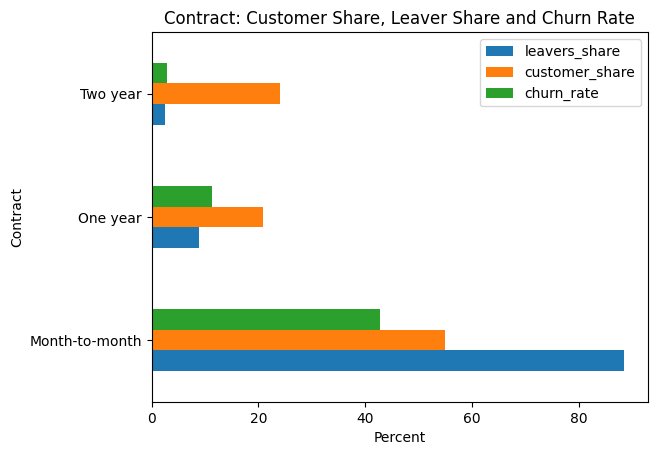

In [ ]:
plot_df.plot(kind = 'barh')
plt.title("Contract: Customer Share, Leaver Share and Churn Rate")
plt.xlabel("Percent")
plt.ylabel('Contract')


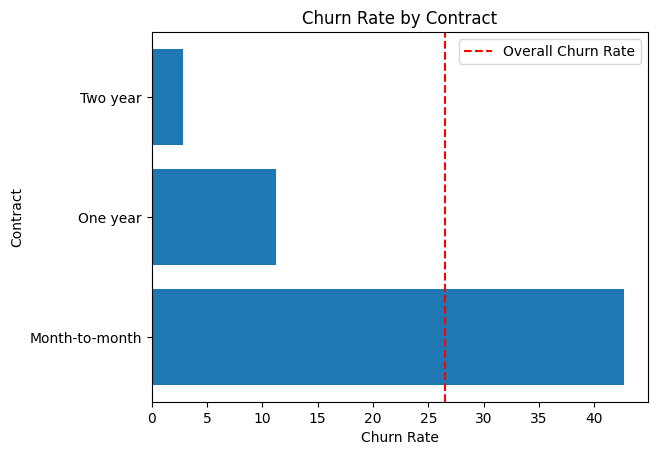

In [ ]:
plt.tight_layout()
plt.barh(churn_rate.index, churn_rate.values)
plt.axvline(customer_left.mean()*100, color='red',linestyle='--', label='Overall Churn Rate')
plt.title("Churn Rate by Contract")
plt.xlabel("Churn Rate")
plt.ylabel('Contract')
plt.legend()

# 5. Customer Service

In [ ]:
support_count = df['TechSupport'].value_counts()
print(support_count)

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64


In [ ]:
support_leavers = df[customer_left]['TechSupport'].value_counts()
print(support_leavers)

TechSupport
No                     1446
Yes                     310
No internet service     113
Name: count, dtype: int64


In [ ]:
print(df[df['InternetService'] == 'No']['TechSupport'].value_counts())

TechSupport
No internet service    1526
Name: count, dtype: int64


In [ ]:
support_churn_rate = customer_left.groupby(df['TechSupport']).mean() * 100

In [ ]:
pd.DataFrame({
    'customers':support_count,
    'leavers': support_leavers,
    'customer_share':support_count / len(df) * 100,
    'leavers_share': support_leavers/support_leavers.sum() * 100,
    'support_churn_rate':support_churn_rate}).round(1)

,customers,leavers,customer_share,leavers_share,support_churn_rate
TechSupport,,,,,
No,3473,1446,49.3,77.4,41.6
No internet service,1526,113,21.7,6.0,7.4
Yes,2044,310,29.0,16.6,15.2


# 6. Churn share by gender


In [ ]:
gender_count = df['gender'].value_counts()
print(gender_count)

gender
Male      3555
Female    3488
Name: count, dtype: int64


In [ ]:
gender_leavers = df[customer_left]['gender'].value_counts()
print(gender_leavers)

gender
Female    939
Male      930
Name: count, dtype: int64


# 7. Churn rate by age group

In [ ]:
age_group = df['SeniorCitizen'].map({1: 'Senior', 0: 'Not Senior Citizen'})
age_count = age_group.value_counts()
print(age_count)

SeniorCitizen
Not Senior Citizen    5901
Senior                1142
Name: count, dtype: int64


In [ ]:
age_leavers = age_group[customer_left].value_counts()
print(age_leavers)

SeniorCitizen
Not Senior Citizen    1393
Senior                 476
Name: count, dtype: int64


1. Tech Support
2. Online/Entertainment Services
3. Churn based on age group and number of dependents, with relation to their respective contract.
4. Age + gender and tenure

In [ ]:
age_churn_rate = customer_left.groupby(age_group).mean()* 100
print(age_churn_rate)

SeniorCitizen
Not Senior Citizen    23.606168
Senior                41.681261
Name: Churn, dtype: float64


## **1. Tech Support**

In [ ]:
pd.DataFrame({
    'customers':age_count,
    'leavers': age_leavers,
    'customer_share':age_count / len(df) * 100,
    'leavers_share': age_leavers/age_leavers.sum() * 100,
    'age_churn_rate':age_churn_rate}).round(1)

,customers,leavers,customer_share,leavers_share,age_churn_rate
SeniorCitizen,,,,,
Not Senior Citizen,5901,1393,83.8,74.5,23.6
Senior,1142,476,16.2,25.5,41.7


In [ ]:
support_by_gender = pd.crosstab(df['gender'],df['TechSupport'], normalize='index')*100
print(support_by_gender)

TechSupport         No  No internet service        Yes
gender                                                
Female       49.139908            21.416284  29.443807
Male         49.479606            21.912799  28.607595


## **2. Online/Entertainment Services**

In [ ]:
pd.crosstab([df['SeniorCitizen'],df['StreamingTV']],df['Churn'],normalize='index')* 100

Churn                                     No        Yes
SeniorCitizen StreamingTV                              
0             No                   69.458988  30.541012
              No internet service  92.672999   7.327001
              Yes                  72.599532  27.400468
1             No                   53.281853  46.718147
              No internet service  90.384615   9.615385
              Yes                  59.965035  40.034965

## **3. Churn based on age group and number of dependents, with relation to their respective contract.**

In [ ]:
pd.crosstab([df['SeniorCitizen'],df['Dependents'],df['Contract']],df['Churn'],normalize='index')* 100

Churn                                           No        Yes
SeniorCitizen Dependents Contract                            
0             No         Month-to-month  58.204467  41.795533
                         One year        88.431877  11.568123
                         Two year        96.649485   3.350515
              Yes        Month-to-month  67.432432  32.567568
                         One year        90.693069   9.306931
                         Two year        97.932817   2.067183
1             No         Month-to-month  44.195251  55.804749
                         One year        83.536585  16.463415
                         Two year        96.899225   3.100775
              Yes        Month-to-month  63.265306  36.734694
                         One year        92.307692   7.692308
                         Two year        87.500000  12.500000

## **8. Joint probability (Services opted by customers) and comparing it with churn rate.**

In [ ]:
internet_df = df[df['InternetService'] != 'No']
internet_left = internet_df['Churn'] == 'Yes'

In [ ]:
print(len(internet_df))

5517


In [ ]:
print(round(internet_left.mean()*100,1))

31.8


In [ ]:
joint_probability = pd.crosstab(internet_df['StreamingTV'],internet_df['StreamingMovies'],normalize=True)*100

In [ ]:
print(joint_probability)

StreamingMovies         No        Yes
StreamingTV                          
No               36.577850  14.355628
Yes              13.902483  35.164038


# Customer Retention Analysis

This notebook works through eight requests from the head of retention and the revenue assurance team at a telecom company. Each request is a business question that is answered with data.

The dataset contains 7,043 customers, one row per customer. `Churn = Yes` indicates that the customer left.

## Request 1: Likelihood of leaving

> What is the likelihood that a randomly selected customer leaves? Does it differ between customer groups?

**Hints**
- Define the event of interest: a customer whose `Churn` value is `Yes`.
- The likelihood is the number of customers who left divided by the total number of customers.
- Compare the result from a small random selection of customers with the result from all customers.
- Repeat the calculation separately for each contract type.

In [ ]:
import random

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
np.random.seed()

for n in [100,500,1000,2000]:
  sample = df.sample(n)
  print(n, (sample['Churn']=='Yes').mean())

100 0.29
500 0.224
1000 0.248
2000 0.2795


## Request 2: Campaign targeting

> Retention plans a save-offer campaign aimed at one customer segment. Every contacted customer has a cost, so the campaign should reach as many leavers as possible without contacting many customers who would have stayed.
>
> Compare these segments, using who left in the period covered by the data:
> - month-to-month contract
> - electronic check payment
> - fiber optic internet
> - month-to-month contract combined with electronic check payment
>
> For each segment, what share of all leavers would the campaign reach, and what share of the contacted customers are leavers? Which segment should the campaign target?

**Hints**
- A segment is the group of customers who meet a condition, such as having a month-to-month contract.
- Two measures are needed for each segment: the share of all leavers who belong to it, and the share of its customers who left.
- Compare both measures with the churn rate of all customers.
- Combining two conditions makes the segment smaller. Observe how each measure changes.
- The two measures are linked through the size of the segment and the overall churn rate. Rebuild one from the other.

In [ ]:
df['Contract'].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

In [ ]:
m2m = df['Contract'] == 'Month-to-month'

In [ ]:
df['PaymentMethod'].unique()

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

In [ ]:
echeck = df['PaymentMethod'] == 'Electronic check'

In [ ]:
df['InternetService'].unique()

array(['DSL', 'Fiber optic', 'No'], dtype=object)

In [ ]:
fiber = df['InternetService'] == 'Fiber optic'

In [ ]:
m2m_fiber = m2m & fiber

In [ ]:
((m2m & customer_left).sum()/customer_left.sum() * 100)

np.float64(88.55002675227395)

In [ ]:
((echeck & customer_left).sum()/customer_left.sum() * 100)

np.float64(57.30337078651685)

In [ ]:
((fiber & customer_left).sum()/customer_left.sum() * 100)

np.float64(69.39539860888175)

In [ ]:
((m2m_fiber & customer_left).sum()/customer_left.sum() * 100)

np.float64(62.172284644194754)

## Request 3: Customer churn and revenue churn

> The board report quotes the customer churn rate. Finance asks what share of monthly revenue was lost to churn, and what the average revenue lost per customer is. Does the revenue figure agree with the customer churn rate?

**Hints**
- A customer who stays contributes no lost revenue. A customer who leaves contributes their monthly charge.
- Create one value per customer on that basis. Its average is the average revenue lost per customer.
- The share of revenue lost is the total revenue lost divided by the total monthly revenue.
- If the two churn figures differ, compare the average monthly charge of customers who left with that of all customers.

In [ ]:
df['MonthlyCharges'].mean()

np.float64(64.76169246059918)

In [ ]:
df[customer_left]['MonthlyCharges'].mean()

np.float64(74.44133226324237)

In [ ]:
df[-customer_left]['MonthlyCharges'].mean()

np.float64(61.26512369540008)

In [ ]:
df[customer_left]['MonthlyCharges'].mean() / df['MonthlyCharges'].mean()

np.float64(1.1494655163394973)

In [ ]:
26.5 * 1.149

30.4485

In [ ]:
df['MonthlyCharges'].describe()

## Request 4: Agent portfolios

> Each retention agent is assigned a portfolio of 20 customers. One agent lost 10 of the 20 in the period, and a manager is considering a performance review.
>
> How unusual is this result if every agent faces the same overall churn rate? At what number of losses should a review be triggered, if the company accepts a 5% chance of reviewing an agent whose result was due to chance?

**Hints**
- The number of customers lost from a portfolio depends on which 20 customers it contains.
- Build many random portfolios of 20 customers and record the number of leavers in each.
- Count the share of portfolios with 10 or more leavers.
- Find the smallest number of leavers for which this share is at most 5%.
- The same chances can be calculated directly from the churn rate and the portfolio size.

In [ ]:
np.random.seed()

In [ ]:
leavers_per_portfolio = []

In [ ]:
for i in range(1000):
  portfolio = df.sample(20)
  leavers_per_portfolio.append((portfolio['Churn'] == 'Yes').sum())

In [ ]:
leavers_per_portfolio = pd.Series(leavers_per_portfolio)

In [ ]:
leavers_per_portfolio.value_counts().sort_index()

In [ ]:
18 + 3 + 1

22

In [ ]:
print((leavers_per_portfolio >= 10).mean())

0.022


In [ ]:
for i in range(5, 15):
  print(i, (leavers_per_portfolio >= i).mean())

## Request 5: Audit size

> Revenue assurance will audit a sample of accounts to verify the average monthly bill. The audit average must fall within 3 of the true average in at least 95% of audits. Every audited account has a cost, so the sample should be no larger than necessary.
>
> How many accounts should be audited?

**Hints**
- One audit gives one average. Repeating the audit shows how much the averages vary.
- For several audit sizes, repeat the audit many times and record the share of audits that fall within 3 of the true average.
- Plot the audit averages for one size and describe the shape.
- The spread of the audit averages depends on the spread of individual bills and on the number of accounts. Use this to calculate the required size directly.

In [ ]:
bills = df['MonthlyCharges']

In [ ]:
tm = bills.mean()

In [ ]:
print(tm)

64.76169246059918


In [ ]:
audit_mean = []

In [ ]:
for i in range(10000):
  audit_mean.append(bills.sample(400).mean())
audit_mean = pd.Series(audit_mean)


In [ ]:
plt.figure(figsize=(10,6))
plt.hist(audit_mean,bins=40, color='skyblue',edgecolor='black')
plt.axvline(tm,color='red',linestyle='--',label='True Avg')
plt.axvline(tm - 3,color='green',linestyle='--',label='Acceptable Range')
plt.axvline(tm + 3,color='green',linestyle='--')

plt.legend()